In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier


In [2]:
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
print(df.shape)
print(df.head())

(253680, 22)
   Diabetes_012  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0           0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1           0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2           0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3           0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4           0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.0  0.0   9.0        

In [3]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [4]:
print(df.describe())

        Diabetes_012         HighBP       HighChol      CholCheck  \
count  253680.000000  253680.000000  253680.000000  253680.000000   
mean        0.296921       0.429001       0.424121       0.962670   
std         0.698160       0.494934       0.494210       0.189571   
min         0.000000       0.000000       0.000000       0.000000   
25%         0.000000       0.000000       0.000000       1.000000   
50%         0.000000       0.000000       0.000000       1.000000   
75%         0.000000       1.000000       1.000000       1.000000   
max         2.000000       1.000000       1.000000       1.000000   

                 BMI         Smoker         Stroke  HeartDiseaseorAttack  \
count  253680.000000  253680.000000  253680.000000         253680.000000   
mean       28.382364       0.443169       0.040571              0.094186   
std         6.608694       0.496761       0.197294              0.292087   
min        12.000000       0.000000       0.000000              0.000000  

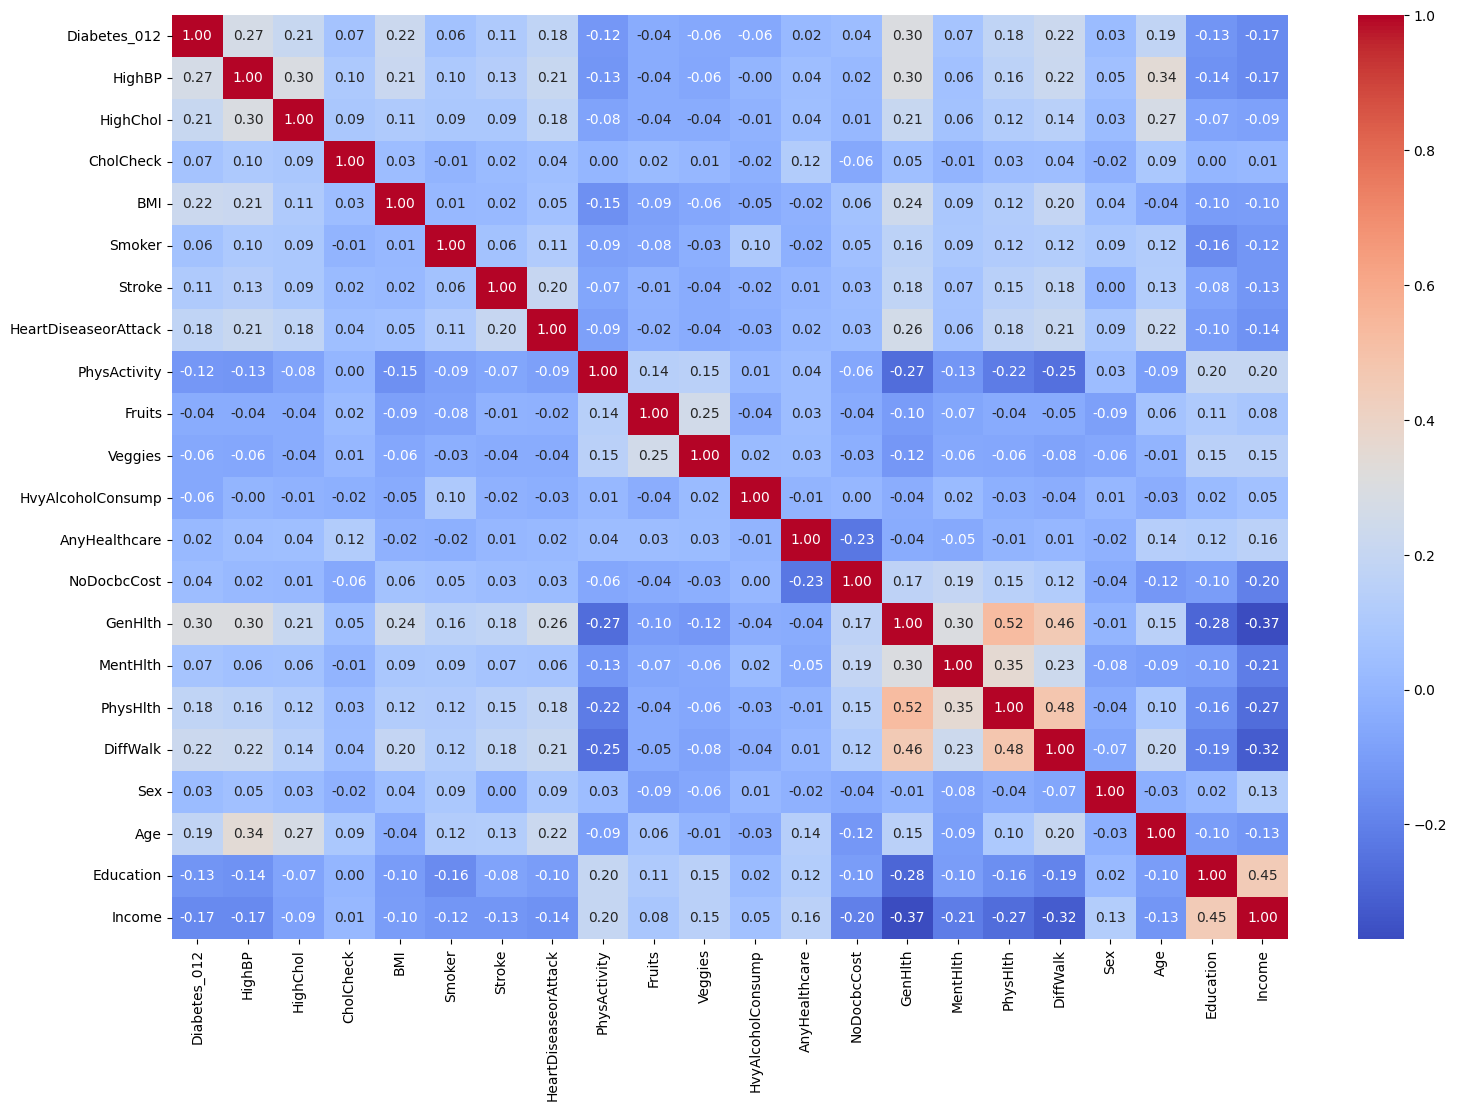

In [5]:
plt.figure(figsize=(18,12))
sns.heatmap(df.corr(), cmap="coolwarm", fmt=".2f", annot=True)
plt.show()

<Axes: xlabel='Diabetes_012', ylabel='count'>

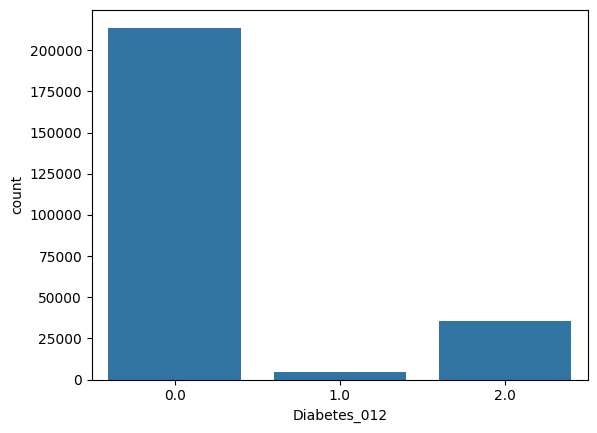

In [6]:
sns.countplot(data=df, x='Diabetes_012')

<Axes: xlabel='Diabetes_012', ylabel='BMI'>

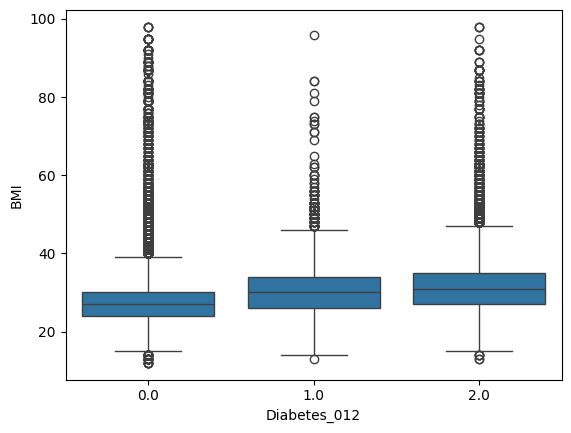

In [7]:
sns.boxplot(data=df, x='Diabetes_012', y='BMI')

<Axes: xlabel='Diabetes_012', ylabel='Age'>

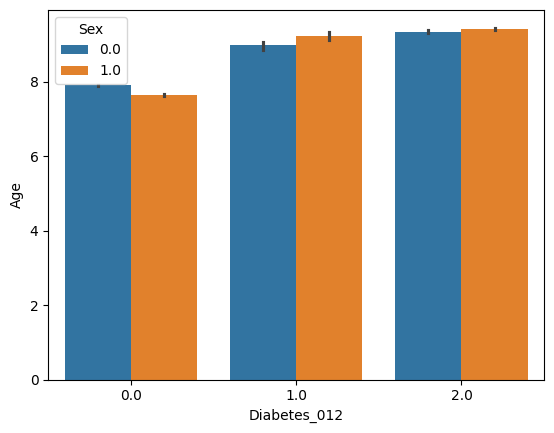

In [8]:

sns.barplot(data=df, x="Diabetes_012", y="Age", hue="Sex")

<Axes: xlabel='HighBP', ylabel='count'>

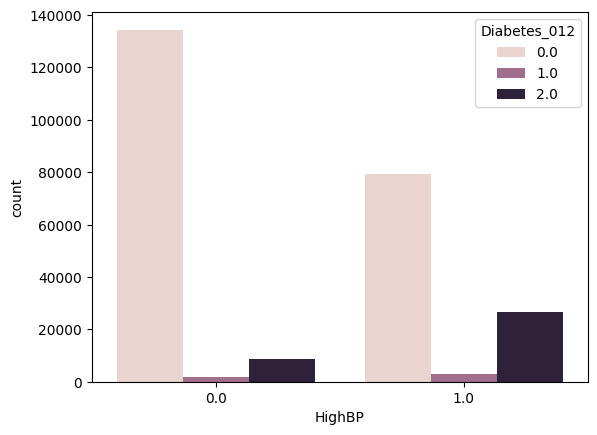

In [9]:
sns.countplot(data=df, x='HighBP', hue='Diabetes_012')

<Axes: xlabel='HighChol', ylabel='count'>

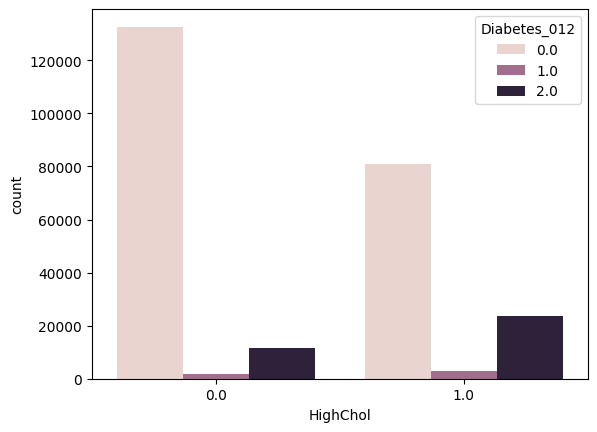

In [10]:
sns.countplot(data=df, x='HighChol', hue='Diabetes_012')

<Axes: xlabel='GenHlth', ylabel='count'>

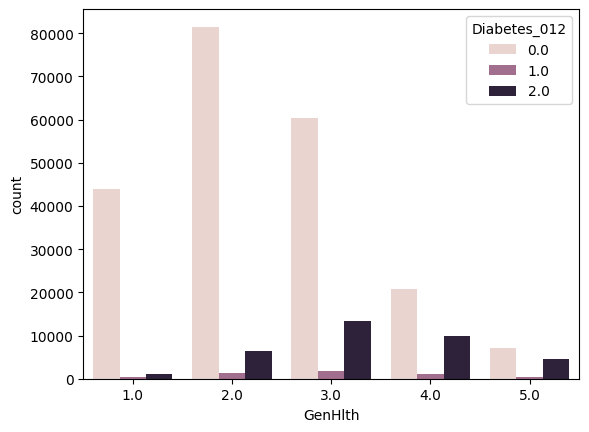

In [11]:
sns.countplot(data=df, x='GenHlth', hue='Diabetes_012')

In [12]:
df['BMI'] = df['BMI'].clip(upper=df['BMI'].quantile(0.99))
df['BMI'].describe()

count    253680.000000
mean         28.277681
std           6.049009
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          50.000000
Name: BMI, dtype: float64

<Axes: xlabel='Diabetes_012', ylabel='BMI'>

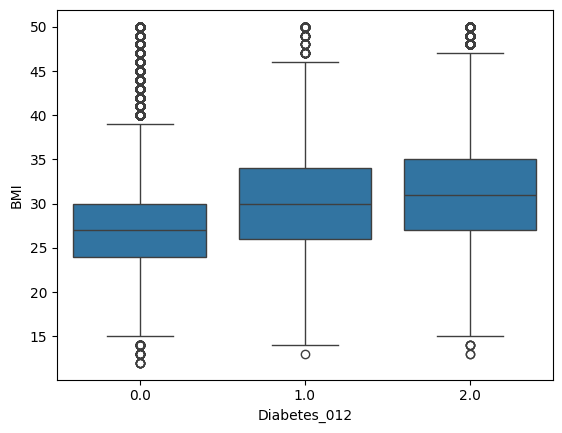

In [13]:
sns.boxplot(data=df, x='Diabetes_012', y='BMI')

In [14]:
x = df.drop(columns="Diabetes_012")
y = df["Diabetes_012"]

x_train , x_test , y_train , y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(x_train, y_train)

y_pred_base = baseline_model.predict(x_test)
print(classification_report(y_test, y_pred_base, zero_division=0))

              precision    recall  f1-score   support

         0.0       0.84      1.00      0.91     42741
         1.0       0.00      0.00      0.00       926
         2.0       0.00      0.00      0.00      7069

    accuracy                           0.84     50736
   macro avg       0.28      0.33      0.30     50736
weighted avg       0.71      0.84      0.77     50736



In [16]:
num_features = ['BMI', 'Age', 'MentHlth', 'PhysHlth']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features)
    ],
    remainder='passthrough'
)

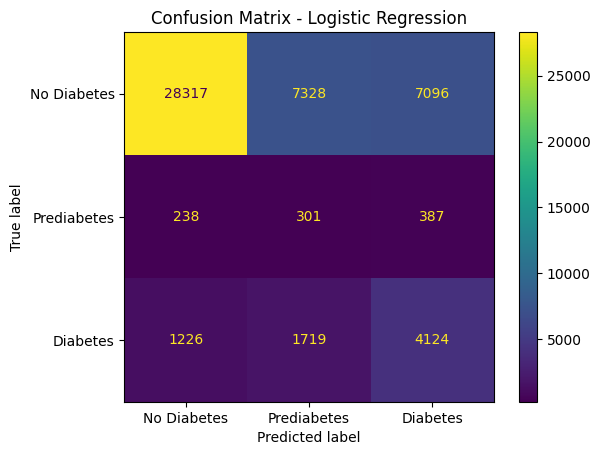

Logistic Regression ROC-AUC Score: 0.7736


In [ ]:
log_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

log_pipeline.fit(x_train, y_train)

y_pred_log = log_pipeline.predict(x_test)

cm_log = confusion_matrix(y_test, y_pred_log)
disp_log = ConfusionMatrixDisplay(confusion_matrix=cm_log, display_labels=['No Diabetes', 'Prediabetes', 'Diabetes'])

disp_log.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

y_prob_log = log_pipeline.predict_proba(x_test)
roc_auc = roc_auc_score(y_test, y_prob_log, multi_class='ovr')
print(f"Logistic Regression ROC-AUC Score: {roc_auc:.4f}")

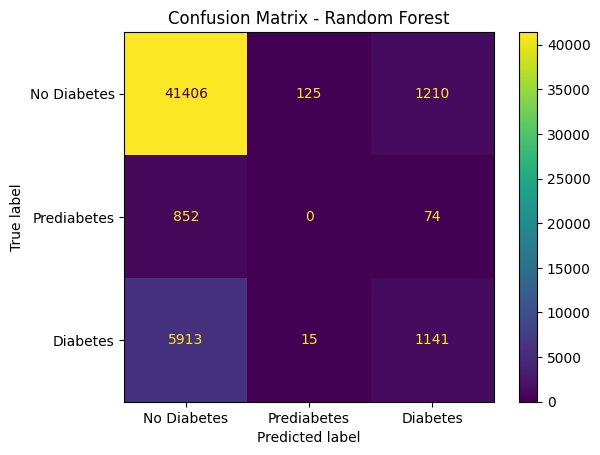

Random Forest ROC-AUC Score: 0.7335


In [28]:

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42))
])

rf_pipeline.fit(x_train, y_train)

y_pred_rf = rf_pipeline.predict(x_test)

cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Diabetes', 'Prediabetes', 'Diabetes'])

disp_rf.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

y_prob_rf = rf_pipeline.predict_proba(x_test)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf, multi_class='ovr')
print(f"Random Forest ROC-AUC Score: {roc_auc_rf:.4f}")

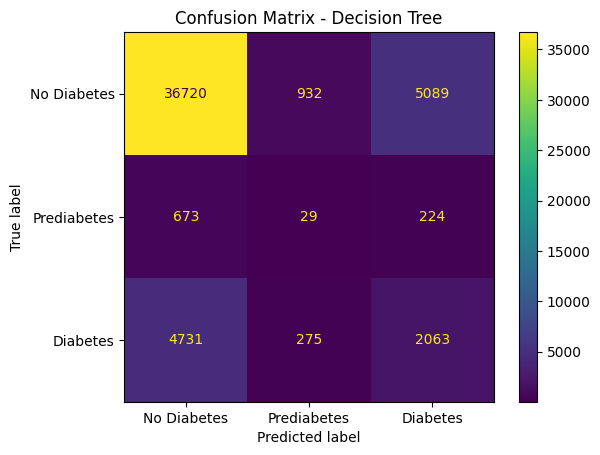

Decision Tree ROC-AUC Score: 0.5605


In [29]:
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

dt_pipeline.fit(x_train, y_train)

y_pred_dt = dt_pipeline.predict(x_test)

cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No Diabetes', 'Prediabetes', 'Diabetes'])

disp_dt.plot()
plt.title("Confusion Matrix - Decision Tree")
plt.show()

y_prob_dt = dt_pipeline.predict_proba(x_test)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt, multi_class='ovr')
print(f"Decision Tree ROC-AUC Score: {roc_auc_dt:.4f}")

                 Feature  Importance  Coefficient
6   HeartDiseaseorAttack    0.709668    -0.709668
1               HighChol    0.426879    -0.426879
5                 Stroke    0.399512    -0.399512
0                 HighBP    0.372992    -0.372992
4                 Smoker    0.360959    -0.360959
16              DiffWalk    0.319584    -0.319584
13               GenHlth    0.316945     0.316945


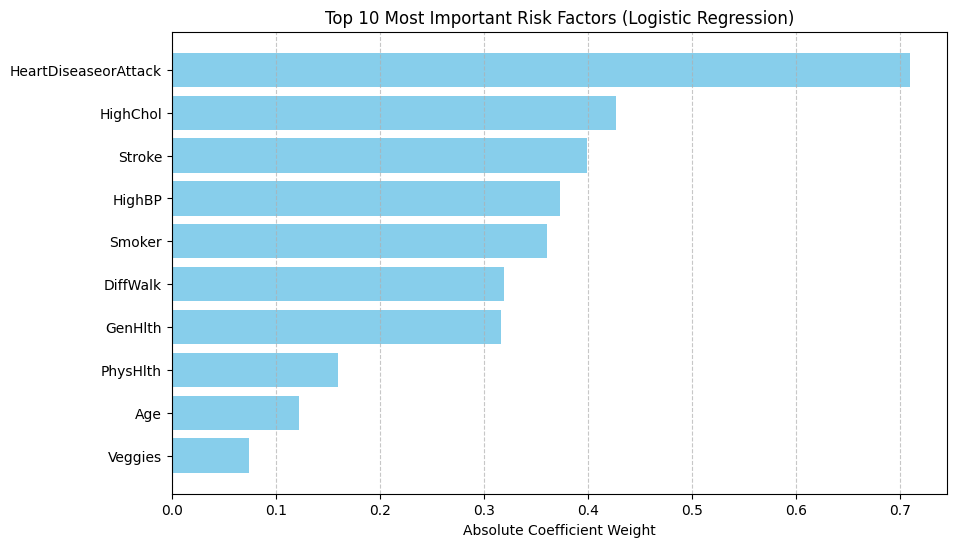

In [30]:
feature_names = x_train.columns
coefficients = log_pipeline.named_steps['classifier'].coef_[0]

if coefficients.ndim > 1:
    coef_abs = np.mean(np.abs(coefficients), axis=0)
    coef_raw = np.mean(coefficients, axis=0)
else:
    coef_abs = np.abs(coefficients)
    coef_raw = coefficients

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': coef_abs,
    'Coefficient': coef_raw
}).sort_values(by='Importance', ascending=False)

print(df_importance.head(7))

plt.figure(figsize=(10, 6))
plt.barh(df_importance['Feature'].head(10)[::-1], df_importance['Importance'].head(10)[::-1], color='skyblue')
plt.xlabel('Absolute Coefficient Weight')
plt.title('Top 10 Most Important Risk Factors (Logistic Regression)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [32]:
import joblib

joblib.dump(log_pipeline, 'diabetes_model.joblib')

['diabetes_model.joblib']